# Aula 05 — AdvogAI: adaptando um LLM ao domínio jurídico com eficiência

**Disciplina: Engenharia de Machine Learning — FIAP PósTech**

---

## 🎯 Objetivo da aula

Nesta aula vamos entender, na prática, como **transfer learning** e **PEFT** (Parameter-Efficient Fine-Tuning) permitem **adaptar um modelo pré-treinado gigante** a um novo domínio **gastando muito menos** memória, tempo e dinheiro.

Usaremos como exemplo o caso da startup **AdvogAI**, que resume contratos jurídicos automaticamente. Ao final, você será capaz de:

1. Entender por que treinar um LLM do zero é inviável para uma startup pequena.
2. Explicar de forma simples o que são **transfer learning**, **fine-tuning completo** e **PEFT** (LoRA/QLoRA).
3. Medir na prática quantos **parâmetros treináveis** cada estratégia exige.
4. Comparar **custo computacional** e **uso de memória** entre fine-tuning completo, LoRA e QLoRA.
5. Avaliar qual estratégia é **viável** para o hardware limitado da AdvogAI.
6. Discutir técnicas reais de adaptação e seus trade-offs (eficiência × qualidade).

## ✅ Pré-requisitos

Antes de executar este notebook, garanta o seguinte:

### 1. Software necessário

| Item | Versão mínima | Observação |
|---|---|---|
| **Python** | 3.10+ | Verifique com `python --version` |
| **Jupyter** | 1.0+ | Para abrir e executar o notebook |
| **NumPy** | 1.24+ | Cálculos de parâmetros e estatísticas |
| **Pandas** | 2.0+ | Tabela comparativa |
| **Matplotlib** | 3.7+ | Visualizações |

Este notebook é **leve e autocontido**: usa apenas `numpy`, `pandas` e `matplotlib`. **Não requer GPU**, internet ou datasets externos — roda em qualquer ambiente local simples.

### 2. Instalação das dependências

**Opção A — no terminal (recomendado):**

```bash
# a partir da pasta 05_transfer_learning_eficiente
pip install -r requirements.txt

# ou, o mínimo para este notebook:
pip install numpy pandas matplotlib jupyter
```

**Opção B — direto no notebook:** execute a célula de instalação logo abaixo (descomente a linha `%pip install ...`).

### 3. Selecionar o kernel correto

No canto superior direito do notebook, clique em **"Select Kernel"** e escolha o interpretador Python onde as dependências foram instaladas. Se aparecer `ModuleNotFoundError`, quase sempre significa que o kernel selecionado não é o mesmo ambiente da instalação — selecione o kernel certo (ou rode a célula de instalação abaixo) e execute novamente.

In [1]:
# (Opcional) Instalar as dependencias diretamente no kernel atual.
# Descomente a linha abaixo caso veja "ModuleNotFoundError" ao rodar as proximas celulas.
%pip install numpy pandas matplotlib

# Verificacao rapida do ambiente
import sys
print("Python:", sys.version.split()[0])
try:
    import numpy, pandas, matplotlib
    print("numpy:", numpy.__version__)
    print("pandas:", pandas.__version__)
    print("matplotlib:", matplotlib.__version__)
    print("Dependencias OK. Pode seguir para a proxima celula.")
except ModuleNotFoundError as e:
    print("Faltando:", e.name)
    print("=> Descomente a linha '%pip install numpy pandas matplotlib' acima e rode esta celula novamente.")

Note: you may need to restart the kernel to use updated packages.
Python: 3.13.14
numpy: 2.5.0
pandas: 3.0.3
matplotlib: 3.11.0
Dependencias OK. Pode seguir para a proxima celula.


## 1. Introdução: a startup AdvogAI

A **AdvogAI** é uma startup que usa IA para **resumir contratos jurídicos automaticamente**. Em vez de um advogado ler dezenas de páginas, o sistema gera um resumo com as cláusulas mais importantes em segundos.

Para isso, a empresa decidiu **reutilizar um LLM pré-treinado** (um modelo de linguagem gigante já treinado em bilhões de palavras) em vez de **criar um modelo do zero**.

### Por que não treinar do zero?

Treinar um LLM do zero exigiria:

- **Bilhões de palavras** de treinamento.
- **Grande capacidade computacional** (centenas de GPUs).
- **Muito tempo e investimento** (meses e milhões de reais).

### O desafio da adaptação

O modelo pré-treinado sabe "português geral", mas ainda precisa **aprender o domínio jurídico**:

- **Termos jurídicos** ("rescisão", "cláusula pétrea", "foro de eleição").
- **Linguagem e estrutura** típicas de contratos.
- **Contexto específico** da área legal.

### As restrições da empresa

| Recurso | Situação da AdvogAI |
|---|---|
| GPUs | Apenas **1 ou 2** |
| Orçamento | **Limitado** |
| Prazo | **Curto** |

```
📄 Contrato → [LLM adaptado ao domínio jurídico] → 📝 Resumo das cláusulas
```

> 🧩 A pergunta central da aula é: **como adaptar um modelo gigante ao domínio jurídico usando pouquíssimos recursos?**

## 2. Conceitos principais

Antes do hands-on, alguns conceitos simples que amarram toda a aula. A ideia é entender **como adaptar** um modelo gastando pouco — não decorar teoria.

### 🔄 Transfer learning

É **reutilizar o conhecimento** de um modelo já treinado. O LLM pré-treinado já aprendeu representações gerais da linguagem; o novo treinamento apenas **ajusta esse conhecimento** para o domínio/tarefa alvo (aqui, contratos jurídicos). Isso **economiza dados** e **acelera** o desenvolvimento.

### 🏋️ Fine-tuning tradicional (completo)

É re-treinar o modelo **atualizando TODOS os parâmetros**. Garante a máxima adaptação, mas tem **custo elevado**: precisa de muitas GPUs, muita memória e tempo. Para um LLM gigante, é inviável para uma startup pequena.

### 🪶 PEFT (Parameter-Efficient Fine-Tuning)

É uma família de técnicas que **ajusta apenas uma pequena fração dos parâmetros** (muitas vezes **< 3%**), mantendo a **maior parte do modelo congelada**. Resultado: adaptação boa com **muito menos memória e custo**.

As principais técnicas de PEFT:

- **Adapters:** pequenas camadas extras inseridas dentro do modelo; só elas são treinadas.
- **LoRA (Low-Rank Adaptation):** em vez de atualizar a matriz de pesos inteira, aprende **duas matrizes pequenas** (decomposição de baixo rank) que representam o ajuste. O modelo original fica **congelado**.
- **QLoRA:** é o **LoRA + quantização**. O modelo base é **quantizado para 4 bits**, reduzindo drasticamente a memória, e o LoRA é treinado por cima. Permite fazer fine-tuning **em uma única GPU**.
- **Prompt/Prefix Tuning:** congela o modelo inteiro e treina apenas **pequenos vetores de entrada** (embeddings/prefixos) que "guiam" o modelo para a tarefa.

### 🤔 Por que adaptar é melhor do que treinar do zero?

Adaptar aproveita **bilhões de palavras já aprendidas**. Você só ensina o "sotaque" do domínio jurídico, gastando **uma fração** dos dados, do tempo e do hardware. Para a AdvogAI, é a diferença entre um projeto **viável** e um projeto **impossível**.

## 3. Hands-on prático

Para manter tudo simples e sem GPU, vamos focar em **um** conceito no hands-on: o **LoRA** (e sua versão **QLoRA**). Vamos **simular** quantos parâmetros cada estratégia treina e estimar o **custo** e a **memória** correspondentes.

Em vez de rodar um LLM real (que exigiria GPU e bibliotecas pesadas), representamos o modelo apenas pelos seus **números de parâmetros**. O foco fica onde importa nesta aula: **entender por que LoRA/QLoRA treinam muito menos parâmetros e cabem no hardware da AdvogAI**.

### A ideia do LoRA em uma linha

Cada camada do LLM tem várias matrizes de pesos `W` de tamanho `d x d` (atenção + MLP). O fine-tuning completo atualiza **todos** os `d × d` valores de cada matriz. O LoRA congela `W` e aprende duas matrizes pequenas `A` (`d x r`) e `B` (`r x d`), com um **rank** `r` bem pequeno (ex.: 8). Assim, treina apenas `2 × d × r` valores por matriz — uma fração minúscula.

Primeiro, os imports e os parâmetros do nosso LLM simulado.

In [2]:
# ------------------------------------------------------------------
# IMPORTS - enxutos para manter o notebook leve e sem GPU
# ------------------------------------------------------------------
import numpy as np                # calculos de parametros e estatisticas
import pandas as pd               # montar a tabela comparativa
import matplotlib.pyplot as plt   # visualizar os resultados

# Semente fixa -> resultados reproduziveis (todos veem numeros parecidos).
np.random.seed(42)

# ------------------------------------------------------------------
# PARAMETROS DO LLM SIMULADO (numeros didaticos, ordem de grandeza real)
# ------------------------------------------------------------------
# Imagine um LLM com N_CAMADAS camadas. Cada camada tem VARIAS matrizes de
# pesos quadradas de tamanho D x D (atencao: Q, K, V, O + MLP). Chamamos
# esse numero de MATRIZES_POR_CAMADA. O total de parametros e, aproximada-
# mente, N_CAMADAS * MATRIZES_POR_CAMADA * D * D -> da ordem de bilhoes,
# como um LLM real de ~7B parametros.
D = 4096                 # dimensao interna do modelo (ex.: 4096)
N_CAMADAS = 32           # numero de camadas do transformer
MATRIZES_POR_CAMADA = 12 # matrizes DxD por camada (atencao + MLP)
RANK_LORA = 8            # 'r' do LoRA: quanto MENOR, menos parametros treinaveis

# Total de parametros do modelo base (aproximacao simplificada de um LLM ~7B).
PARAMS_TOTAIS = N_CAMADAS * MATRIZES_POR_CAMADA * D * D

print(f"Parametros totais (aprox.): {PARAMS_TOTAIS:,}  (~{PARAMS_TOTAIS/1e9:.1f} bilhoes)")
print(f"LLM simulado: {N_CAMADAS} camadas x {MATRIZES_POR_CAMADA} matrizes de {D}x{D}")

Parametros totais (aprox.): 6,442,450,944  (~6.4 bilhoes)
LLM simulado: 32 camadas x 12 matrizes de 4096x4096


In [3]:
# ==================================================================
# FUNCAO DE ANALISE - o coracao do experimento
# ==================================================================
# OBJETIVO: para cada ESTRATEGIA de adaptacao, calcular:
#   - quantos parametros sao realmente TREINADOS (atualizados),
#   - o custo computacional RELATIVO (proporcional aos treinaveis),
#   - a memoria estimada para treinar.
#
# POR QUE SIMULAR em vez de treinar de verdade?
#   - Treinar um LLM real exigiria GPU, dataset juridico e bibliotecas
#     pesadas. Nesta aula o foco NAO e a qualidade do resumo, e sim
#     ENTENDER por que LoRA/QLoRA treinam MUITO menos parametros e
#     cabem em pouca memoria. Para isso, basta CONTAR os parametros.
#
# REGRA DE MEMORIA (simplificada, so para comparar ordens de grandeza):
#   - O modelo BASE precisa ser carregado na memoria para rodar. Em 16 bits
#     (padrao), cada parametro ocupa ~2 bytes. Em 4 bits (QLoRA), ~0.5 byte.
#   - O TREINO gasta memoria extra so para os parametros TREINAVEIS
#     (gradientes + estados do otimizador). Usamos ~16 bytes por parametro
#     treinavel como aproximacao didatica.


def analisar_estrategia(nome, params_treinaveis, bytes_por_param_base):
    """Calcula parametros treinaveis, custo e memoria de uma estrategia.

    Parametros
    ----------
    nome                 : nome da estrategia (ex.: 'Fine-tuning completo').
    params_treinaveis    : quantos parametros essa estrategia atualiza.
    bytes_por_param_base : quanto cada parametro do MODELO BASE ocupa em
                           memoria. 16 bits = 2 bytes; 4 bits (QLoRA) = 0.5.

    Retorna
    -------
    dict com metricas prontas para a tabela comparativa.
    """
    # Fracao do modelo que e treinada (ex.: 0.02 = 2% dos parametros).
    fracao = params_treinaveis / PARAMS_TOTAIS

    # Memoria para CARREGAR o modelo base (todos os parametros).
    mem_base_gb = PARAMS_TOTAIS * bytes_por_param_base / 1e9

    # Memoria EXTRA de treino: so os parametros treinaveis geram gradientes
    # e estados do otimizador (~16 bytes por parametro treinavel).
    mem_treino_gb = params_treinaveis * 16 / 1e9

    # Memoria total estimada = carregar o modelo + overhead de treino.
    mem_total_gb = mem_base_gb + mem_treino_gb

    # Custo computacional RELATIVO: proporcional a quantos parametros sao
    # atualizados a cada passo. Usamos o fine-tuning completo como 100%.
    custo_relativo = fracao  # sera normalizado para % depois

    return {
        "Estrategia": nome,
        "Parametros treinaveis": params_treinaveis,
        "% do modelo": fracao * 100,
        "Custo relativo": custo_relativo,
        "Memoria estimada (GB)": mem_total_gb,
    }


print("Funcao 'analisar_estrategia' pronta para uso.")

Funcao 'analisar_estrategia' pronta para uso.


### Cenário A — Fine-tuning completo

O fine-tuning tradicional atualiza **todos** os parâmetros do modelo. É a adaptação mais poderosa, mas a mais cara. Vamos ver o tamanho do "monstro" que a AdvogAI teria que treinar.

In [4]:
# Cenario A - Fine-tuning completo: TREINA TODOS os parametros.
# Modelo base carregado em 16 bits (2 bytes por parametro).
res_a = analisar_estrategia(
    nome="Fine-tuning completo",
    params_treinaveis=PARAMS_TOTAIS,      # 100% dos parametros
    bytes_por_param_base=2,               # 16 bits
)

print("=== Cenario A - Fine-tuning completo ===")
print(f"Parametros treinaveis : {res_a['Parametros treinaveis']:,}")
print(f"% do modelo treinado  : {res_a['% do modelo']:.2f}%")
print(f"Memoria estimada      : {res_a['Memoria estimada (GB)']:.1f} GB")

=== Cenario A - Fine-tuning completo ===
Parametros treinaveis : 6,442,450,944
% do modelo treinado  : 100.00%
Memoria estimada      : 116.0 GB


### Cenário B — LoRA

O LoRA **congela** o modelo base e treina apenas duas matrizes pequenas por camada (`A` de `D x r` e `B` de `r x D`). Com `r = 8`, o número de parâmetros treináveis despenca.

In [5]:
# Cenario B - LoRA: para cada matriz DxD, treina 2 matrizes pequenas (A e B).
# Treinaveis por matriz = 2 * D * r. Total = N_CAMADAS * MATRIZES_POR_CAMADA * 2 * D * r.
params_lora = N_CAMADAS * MATRIZES_POR_CAMADA * 2 * D * RANK_LORA

# O modelo base continua carregado em 16 bits (2 bytes), so que CONGELADO.
res_b = analisar_estrategia(
    nome="LoRA (r=8)",
    params_treinaveis=params_lora,
    bytes_por_param_base=2,               # 16 bits
)

print("=== Cenario B - LoRA (r=8) ===")
print(f"Parametros treinaveis : {res_b['Parametros treinaveis']:,}")
print(f"% do modelo treinado  : {res_b['% do modelo']:.3f}%")
print(f"Memoria estimada      : {res_b['Memoria estimada (GB)']:.1f} GB")

reducao = res_a['Parametros treinaveis'] / res_b['Parametros treinaveis']
print(f"\nO LoRA treina ~{reducao:,.0f}x MENOS parametros que o fine-tuning completo.")

=== Cenario B - LoRA (r=8) ===
Parametros treinaveis : 25,165,824
% do modelo treinado  : 0.391%
Memoria estimada      : 13.3 GB

O LoRA treina ~256x MENOS parametros que o fine-tuning completo.


### Cenário C — QLoRA

O QLoRA usa o **mesmo LoRA**, mas **quantiza o modelo base para 4 bits** (0.5 byte por parâmetro no lugar de 2). Isso não muda os parâmetros treináveis, mas **reduz drasticamente a memória** para carregar o modelo — o que permite treinar em **uma única GPU**.

In [6]:
# Cenario C - QLoRA: LoRA + modelo base QUANTIZADO para 4 bits (0.5 byte/param).
# Mesmos parametros treinaveis do LoRA, mas modelo base ocupa ~4x menos memoria.
res_c = analisar_estrategia(
    nome="QLoRA (4 bits + r=8)",
    params_treinaveis=params_lora,        # igual ao LoRA
    bytes_por_param_base=0.5,             # 4 bits
)

print("=== Cenario C - QLoRA (4 bits + r=8) ===")
print(f"Parametros treinaveis : {res_c['Parametros treinaveis']:,}")
print(f"% do modelo treinado  : {res_c['% do modelo']:.3f}%")
print(f"Memoria estimada      : {res_c['Memoria estimada (GB)']:.1f} GB")

economia_mem = res_b['Memoria estimada (GB)'] / res_c['Memoria estimada (GB)']
print(f"\nO QLoRA usa ~{economia_mem:.1f}x MENOS memoria que o LoRA em 16 bits.")

=== Cenario C - QLoRA (4 bits + r=8) ===
Parametros treinaveis : 25,165,824
% do modelo treinado  : 0.391%
Memoria estimada      : 3.6 GB

O QLoRA usa ~3.7x MENOS memoria que o LoRA em 16 bits.


## 4. Comparação dos resultados

Vamos consolidar os três cenários em uma **tabela** e, em seguida, em **gráficos** para visualizar a diferença de parâmetros treináveis e memória.

Para decidir a **viabilidade**, assumimos que a AdvogAI tem **1 GPU de 24 GB**. Uma estratégia é viável se a memória estimada couber nesse limite.

In [7]:
# Limite de hardware da AdvogAI: 1 GPU com 24 GB.
LIMITE_GPU_GB = 24

# Custo relativo normalizado: fine-tuning completo = 100%.
custo_base = res_a["Custo relativo"]

def linha(res):
    """Monta uma linha da tabela comparativa a partir de um resultado."""
    viavel = res["Memoria estimada (GB)"] <= LIMITE_GPU_GB
    return {
        "Cenario": res["Estrategia"],
        "Params treinaveis": f"{res['Parametros treinaveis']:,}",
        "% do modelo": f"{res['% do modelo']:.3f}%",
        "Custo relativo": f"{res['Custo relativo'] / custo_base * 100:.2f}%",
        "Memoria (GB)": round(res["Memoria estimada (GB)"], 1),
        "Viavel (1 GPU 24GB)?": "Sim" if viavel else "Nao",
    }

tabela = pd.DataFrame([linha(res_a), linha(res_b), linha(res_c)])
tabela

,Cenario,Params treinaveis,% do modelo,Custo relativo,Memoria (GB),Viavel (1 GPU 24GB)?
0,Fine-tuning completo,"6,442,450,944",100.000%,100.00%,116.0,Nao
1,LoRA (r=8),"25,165,824",0.391%,0.39%,13.3,Sim
2,QLoRA (4 bits + r=8),"25,165,824",0.391%,0.39%,3.6,Sim


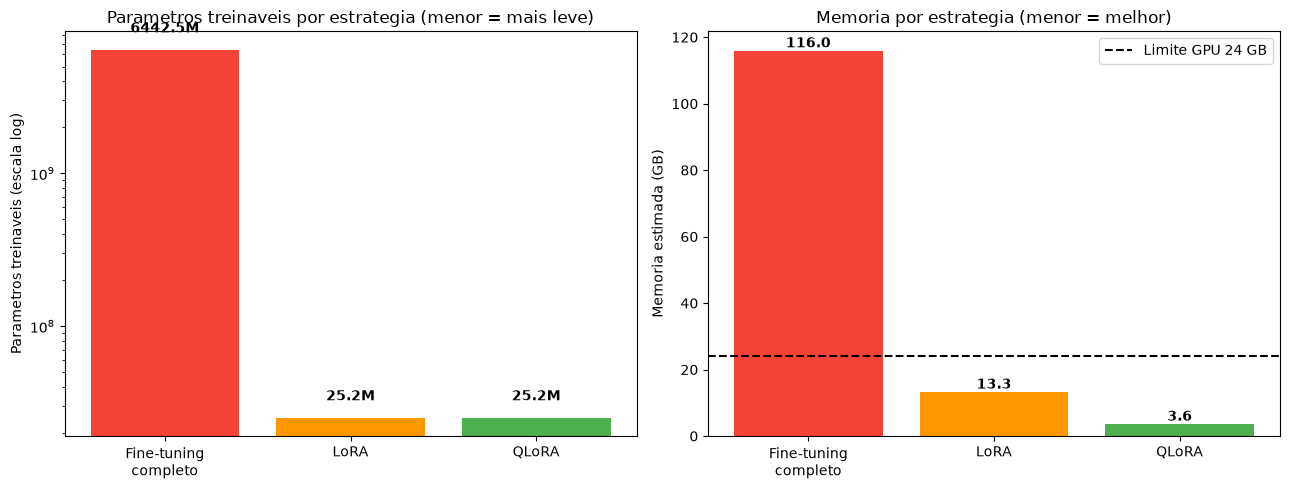

In [8]:
# Graficos comparativos: parametros treinaveis e memoria estimada.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cenarios = ["Fine-tuning\ncompleto", "LoRA", "QLoRA"]
params_vals = [res_a["Parametros treinaveis"], res_b["Parametros treinaveis"], res_c["Parametros treinaveis"]]
mem_vals = [res_a["Memoria estimada (GB)"], res_b["Memoria estimada (GB)"], res_c["Memoria estimada (GB)"]]
cores = ["#F44336", "#FF9800", "#4CAF50"]  # vermelho, laranja, verde

# Grafico 1: parametros treinaveis (escala log, pois a diferenca e enorme).
axes[0].bar(cenarios, params_vals, color=cores)
axes[0].set_yscale("log")
axes[0].set_ylabel("Parametros treinaveis (escala log)")
axes[0].set_title("Parametros treinaveis por estrategia (menor = mais leve)")
for i, v in enumerate(params_vals):
    axes[0].text(i, v * 1.3, f"{v/1e6:.1f}M", ha="center", fontweight="bold")

# Grafico 2: memoria estimada. Linha tracejada = limite da GPU (24 GB).
axes[1].bar(cenarios, mem_vals, color=cores)
axes[1].axhline(LIMITE_GPU_GB, color="black", linestyle="--", label=f"Limite GPU {LIMITE_GPU_GB} GB")
axes[1].set_ylabel("Memoria estimada (GB)")
axes[1].set_title("Memoria por estrategia (menor = melhor)")
axes[1].legend()
for i, v in enumerate(mem_vals):
    axes[1].text(i, v + 1, f"{v:.1f}", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

## 5. Discussão técnica: como adaptar de verdade?

Na simulação apenas **contamos parâmetros e estimamos memória**. No mundo real, a adaptação eficiente vem de técnicas concretas. Você **não precisa implementar todas** — basta entender como cada uma ajudaria a AdvogAI:

| Técnica | Ideia central | Como ajuda a AdvogAI |
|---|---|---|
| **Transfer learning** | Reutilizar um modelo pré-treinado | Aproveita bilhões de palavras já aprendidas |
| **Fine-tuning completo** | Atualizar todos os parâmetros | Adaptação máxima, porém caro e inviável na startup |
| **Adapters** | Camadas pequenas treináveis inseridas no modelo | Adapta com poucos parâmetros extras |
| **LoRA** | Aprender matrizes de baixo rank (A e B) | Treina < 1% dos parâmetros |
| **QLoRA** | LoRA + modelo base em 4 bits | Cabe em 1 GPU; memória mínima |
| **Prompt/Prefix Tuning** | Treinar só vetores de entrada | Congela o modelo; ajuste ultraleve |
| **Congelamento de camadas** | Treinar só as camadas finais | Menos memória e tempo de treino |
| **Redução de precisão** | Pesos em 8/4 bits (quantização) | Menos memória por parâmetro |

> 💡 Na prática, combina-se várias ideias. O caminho que a AdvogAI adotou — **modelo pré-treinado + LoRA + quantização 4 bits (QLoRA)** — é hoje um dos jeitos mais populares de adaptar LLMs com **1 única GPU**.

### ⚖️ Trade-offs entre eficiência e qualidade

PEFT economiza muito, mas há um equilíbrio. Um `rank` muito baixo no LoRA ou uma quantização agressiva demais podem **limitar a qualidade** do resumo. O objetivo é achar o ponto em que a adaptação fica **barata e leve o bastante** para o hardware, **mantendo qualidade suficiente** para resumir contratos de forma confiável.

## 6. Conclusão

Respondendo às perguntas centrais da aula:

**1. Treinar do zero seria viável para a AdvogAI?**
❌ **Não.** Exigiria bilhões de palavras, centenas de GPUs e meses de trabalho — muito além do orçamento e do prazo da startup.

**2. Fine-tuning completo seria viável com os recursos da startup?**
❌ **Dificilmente.** Atualizar 100% dos parâmetros do LLM consome memória e custo altíssimos, não cabendo em 1 ou 2 GPUs.

**3. LoRA ou QLoRA tornam o projeto mais realista?**
✅ **Sim.** O **LoRA** treina uma fração mínima dos parâmetros (< 1%), e o **QLoRA** ainda quantiza o modelo base para 4 bits, reduzindo a memória a ponto de caber em **uma única GPU**.

**4. Qual é o impacto da adaptação eficiente no prazo e no custo?**
Menos parâmetros treináveis e menos memória significam **treinos mais rápidos**, **hardware mais barato** e **iterações mais frequentes** — a AdvogAI consegue entregar o produto dentro do prazo e do orçamento.

**5. Quais trade-offs existem entre eficiência e qualidade?**
Técnicas muito agressivas (rank baixo, quantização forte) podem reduzir a qualidade da adaptação. O segredo é garantir que o resumo continue **bom o suficiente** para o negócio, equilibrando **custo**, **velocidade** e **qualidade**.

### 📌 Principais aprendizados

1. **Transfer learning** reaproveita conhecimento pré-treinado, economizando dados e tempo.
2. **Fine-tuning completo** adapta ao máximo, mas é caro e pesado.
3. **PEFT** (LoRA/QLoRA) treina **< 3%** dos parâmetros, mantendo o modelo base congelado.
4. **QLoRA** = LoRA + quantização 4 bits → cabe em **1 GPU**.
5. Medir parâmetros treináveis e memória é essencial para avaliar **viabilidade** em cenários reais.

### 🚀 Próximos passos sugeridos

- Variar o `RANK_LORA` (ex.: 4, 16, 64) e observar o efeito nos parâmetros treináveis.
- Simular um modelo maior (mais camadas ou `D` maior) e ver o impacto na memória.
- Explorar, em um próximo módulo, LoRA/QLoRA em um LLM **real** com a biblioteca `peft` da Hugging Face.

---

*Material da Aula 05 — Engenharia de Machine Learning — FIAP PosTech.*